# Notebook 9d — `9d_sectors_7var`

## Overview

**Purpose:** Robustness comparison for the 17 sector results using the seven disaggregated flood components instead of the three composite dimensions. Compared against the 3-dimension sector file (9b) in Notebook 9e.

## Data requirements

This notebook runs on the model-ready panel exported by Notebook 8; no raw data
download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Model-ready panel (`transformed` + `pre_transform` sheets) | Notebook 8 | `data/processed/8_panel_data.xlsx` |

## Workflow

| Step | Description |
|---|---|
| 1 | Load the panel and define the flood predictors and controls |
| 2 | Pre-estimation tests (missing values, VIF, panel balance, predictor correlation) |
| 3 | Estimator selection — CEM vs FE vs RE (Chow, LM, Hausman/Mundlak) |
| 4 | Significance across the 17 sectors — uncorrected vs BH-FDR, per flood dimension |
| 5 | Clustered vs Driscoll–Kraay — per-sector comparison and per-sector Pesaran CD test |
| 6 | Model evaluation and robustness (residual diagnostics, control ladder, SE and sample) |
| 7 | Model fit summary per sector (within-R², AIC, BIC, RMSE) and aggregate |
| 8 | Save per-sector results and the master sector table for the dashboard |

## Outputs

| File | Description |
|---|---|
| `fit_9d.json` | Per-sector × per-component coefficients, BH-FDR p-values, evidence flags |

---
## STEP 1 — Load the panel and define the 7-component specification

Load the Notebook 8 panel, log-transform the six raw damage/casualty components (plus event count), and define the controls.

In [2]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Load the panel
# ═════════════════════════════════════════════════════════════
import numpy as np, pandas as pd
from linearmodels.panel import PanelOLS, RandomEffects, PooledOLS
from numpy.linalg import inv
from scipy.stats import chi2, jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

PANEL_PATH = "../data/processed/8_panel_data.xlsx"
_t = pd.read_excel(PANEL_PATH, sheet_name="transformed")
_p = pd.read_excel(PANEL_PATH, sheet_name="pre_transform")
_id = ["bps_kab_code","year"]; _rc = [c for c in _p.columns if c not in _t.columns]
panel = _t.merge(_p[_id+_rc], on=_id, how="left").sort_values(["bps_kab_code","year"])
if not all(c in panel.columns for c in ["deaths","missing","injured","house_flooded","house_damaged","fasum_damaged"]):
    raise ValueError("Raw components missing — re-run corrected nb8 (exports them to pre_transform).")

COMPONENTS = ["deaths","missing","injured","house_flooded","house_damaged","fasum_damaged"]
for c in COMPONENTS:
    panel[f"{c}_log"] = np.log1p(panel[c])
FLOOD = ["event_count_log"] + [f"{c}_log" for c in COMPONENTS]
CONTROLS = ["log_population", "rls_years"]
X = FLOOD + CONTROLS
pdat = panel.set_index(["bps_kab_code","year"])
print(f"Loaded {len(panel)} obs | flood predictors: {len(FLOOD)} | {FLOOD}")

Loaded 5140 obs | flood predictors: 7 | ['event_count_log', 'deaths_log', 'missing_log', 'injured_log', 'house_flooded_log', 'house_damaged_log', 'fasum_damaged_log']


## STEP 2 — Pre-estimation tests

In [4]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Pre-estimation tests
# ═════════════════════════════════════════════════════════════
# missing values
print("Missing values per model column:")
print(panel[X].isna().sum().to_string())
print()
# multicollinearity (VIF) + correlation
Xc = panel[X].dropna(); Xn = (Xc - Xc.mean())/(Xc.std()+1e-12)
vif = pd.Series(np.diag(inv(np.corrcoef(Xn, rowvar=False))), index=X)
print("VIF (multicollinearity):"); print(vif.round(2).to_string())
print(f"  max VIF = {vif.max():.2f}  ({'OK <5' if vif.max()<5 else 'CAUTION >5'})\n")
# panel balance
bc = panel.groupby("bps_kab_code")["year"].count()
print(f"Panel balance: {bc.min()}-{bc.max()} years per regency "
      f"({'balanced' if bc.nunique()==1 else 'unbalanced'}), N={panel.bps_kab_code.nunique()}")

Missing values per model column:
event_count_log      0
deaths_log           0
missing_log          0
injured_log          0
house_flooded_log    0
house_damaged_log    0
fasum_damaged_log    0
log_population       0
rls_years            0

VIF (multicollinearity):
event_count_log      3.48
deaths_log           1.81
missing_log          1.42
injured_log          1.37
house_flooded_log    2.98
house_damaged_log    1.72
fasum_damaged_log    1.59
log_population       1.20
rls_years            1.02
  max VIF = 3.48  (OK <5)

Panel balance: 10-10 years per regency (balanced), N=514


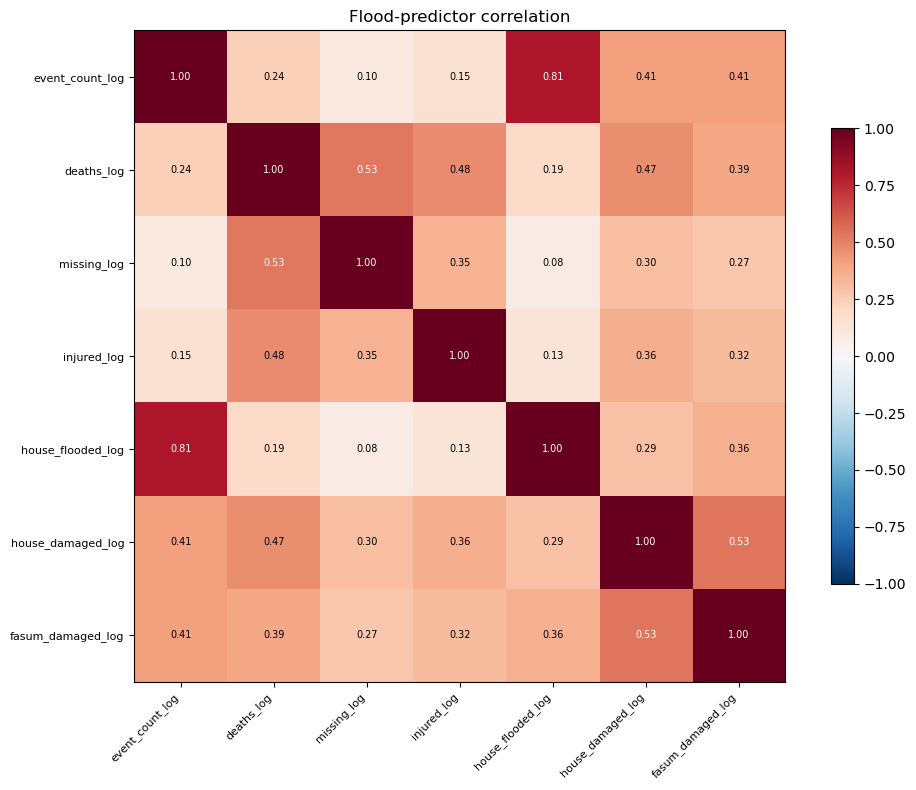

In [5]:
# correlation heatmap of flood predictors
cc = panel[FLOOD].corr()
fig, ax = plt.subplots(figsize=(1.2*len(FLOOD)+2, 1.0*len(FLOOD)+1))
im = ax.imshow(cc.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FLOOD))); ax.set_xticklabels(FLOOD, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(FLOOD))); ax.set_yticklabels(FLOOD, fontsize=8)
for i in range(len(FLOOD)):
    for j in range(len(FLOOD)):
        ax.text(j, i, f"{cc.values[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(cc.values[i,j])>0.5 else "black")
plt.colorbar(im, shrink=0.7); ax.set_title("Flood-predictor correlation"); plt.tight_layout(); plt.show()

## STEP 3 — Estimator selection — CEM vs FE vs RE (Chow · LM · Hausman)

In [7]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Estimator selection — CEM vs FE vs RE
# ═════════════════════════════════════════════════════════════
Y = "grdp_growth_pct"
sub = pdat[[Y]+X].dropna()
cem = PooledOLS(sub[Y], sub[X].assign(const=1)).fit()
fe  = PanelOLS(sub[Y], sub[X], entity_effects=True, time_effects=True,
               drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
re  = RandomEffects(sub[Y], sub[X].assign(const=1)).fit()
print("ESTIMATORS")
print(f"  CEM (Pooled OLS): R2={cem.rsquared:.4f}")
print(f"  Fixed Effects   : within-R2={fe.rsquared_within:.4f}")
print(f"  Random Effects  : R2={re.rsquared:.4f}")

print(f"\n[Chow] F-test entity effects (CEM vs FE): F={fe.f_pooled.stat:.2f}, p={fe.f_pooled.pval:.4g}")
print("   -> " + ("entity effects significant -> FE over CEM" if fe.f_pooled.pval<0.05 else "CEM adequate"))

_u = pd.DataFrame({"u": cem.resids.values}, index=cem.resids.index)
_g = _u.groupby(level=0)["u"]; _T=_g.count(); _n=len(_u)
if _T.nunique()==1:
    LM=(_n/(2*(_T.iloc[0]-1)))*((_g.sum()**2).sum()/(_u["u"]**2).sum()-1)**2
    print(f"[LM]   Breusch-Pagan (CEM vs RE): LM={LM:.2f}, p={1-chi2.cdf(LM,1):.4g}")
    print("   -> " + ("individual effects present -> panel needed" if (1-chi2.cdf(LM,1))<0.05 else "no individual effects"))

common=[c for c in FLOOD if c in fe.params.index and c in re.params.index]
d=(fe.params[common]-re.params[common]).values
vd=(fe.cov.loc[common,common]-re.cov.loc[common,common]).values
h=float(d.T@np.linalg.pinv(vd)@d)
print(f"[Hausman] FE vs RE: chi2={h:.2f}, p={1-chi2.cdf(h,len(common)):.4g}")
flips=sum(1 for v in common if fe.params[v]*re.params[v]<0)
if h<0: print("   -> NEGATIVE (clustered-SE artifact); decide via coefficient gaps + theory")
print(f"   FE vs RE sign flips: {flips} -> "+("RE biased -> FE consistent" if flips else "similar"))
print("\nDECISION: Fixed Effects (Chow+LM reject pooled; FE/RE divergence + theory -> RE inconsistent).")

ESTIMATORS
  CEM (Pooled OLS): R2=0.0112
  Fixed Effects   : within-R2=0.0110
  Random Effects  : R2=0.0119

[Chow] F-test entity effects (CEM vs FE): F=20.08, p=0
   -> entity effects significant -> FE over CEM
[LM]   Breusch-Pagan (CEM vs RE): LM=223.88, p=0
   -> individual effects present -> panel needed
[Hausman] FE vs RE: chi2=-125.48, p=1
   -> NEGATIVE (clustered-SE artifact); decide via coefficient gaps + theory
   FE vs RE sign flips: 3 -> RE biased -> FE consistent

DECISION: Fixed Effects (Chow+LM reject pooled; FE/RE divergence + theory -> RE inconsistent).


## STEP 4 — Significance across 17 sectors — BH-FDR vs uncorrected

17 sectors = 17 simultaneous tests per flood dimension. Without correction ~1 in 20 is a false positive. We show **both** uncorrected and BH-FDR-corrected significance so the effect of multiple-testing control is explicit. BH-FDR is applied per dimension (each dimension = its own family).

In [9]:
# ═════════════════════════════════════════════════════════════
# STEP 4 — Significance across 17 sectors — BH-FDR vs uncorrected
# ═════════════════════════════════════════════════════════════
SECTORS = ["grdp_A_agriculture","grdp_B_mining","grdp_C_manufacturing","grdp_D_electricity",
           "grdp_E_water","grdp_F_construction","grdp_G_trade","grdp_H_transport",
           "grdp_I_accommodation","grdp_J_infocomm","grdp_K_finance","grdp_L_realestate",
           "grdp_MN_business","grdp_O_government","grdp_P_education","grdp_Q_health","grdp_RSTU_other"]
for s in SECTORS:
    if f"{s}_growth" not in panel.columns:
        g = panel.groupby("bps_kab_code")[s].pct_change()*100
        g = g.replace([np.inf,-np.inf],np.nan); lo,hi=g.quantile([.01,.99]); panel[f"{s}_growth"]=g.clip(lo,hi)
pdat = panel.set_index(["bps_kab_code","year"])

rows=[]
for s in SECTORS:
    sub=pdat[[f"{s}_growth"]+X].dropna()
    r=PanelOLS(sub[f"{s}_growth"],sub[X],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    row={"sector":s.replace("grdp_","")}
    for f in FLOOD:
        row[f"b_{f}"]=r.params[f]; row[f"p_{f}"]=r.pvalues[f]
    rows.append(row)
res=pd.DataFrame(rows)
# BH per flood dimension
for f in FLOOD:
    res[f"pBH_{f}"]=multipletests(res[f"p_{f}"].values,method="fdr_bh")[1]
    res[f"sigRAW_{f}"]=res[f"p_{f}"]<0.05
    res[f"sigBH_{f}"]=res[f"pBH_{f}"]<0.05

print("Significant sectors — UNCORRECTED vs BH-FDR (per flood dimension):\n")
for f in FLOOD:
    raw=list(res.loc[res[f"sigRAW_{f}"],"sector"])
    bh =list(res.loc[res[f"sigBH_{f}"],"sector"])
    print(f"  {f}:")
    print(f"    uncorrected (p<0.05): {len(raw)} -> {raw if raw else 'none'}")
    print(f"    BH-FDR      (p<0.05): {len(bh)} -> {bh if bh else 'none'}")
    print(f"    dropped by correction: {sorted(set(raw)-set(bh)) or 'none'}\n")
print("  Interpretation: sectors that survive BH-FDR are the defensible claims;")
print("  those dropped were likely false positives from multiple testing.")

Significant sectors — UNCORRECTED vs BH-FDR (per flood dimension):

  event_count_log:
    uncorrected (p<0.05): 3 -> ['F_construction', 'G_trade', 'Q_health']
    BH-FDR      (p<0.05): 2 -> ['G_trade', 'Q_health']
    dropped by correction: ['F_construction']

  deaths_log:
    uncorrected (p<0.05): 2 -> ['C_manufacturing', 'J_infocomm']
    BH-FDR      (p<0.05): 0 -> none
    dropped by correction: ['C_manufacturing', 'J_infocomm']

  missing_log:
    uncorrected (p<0.05): 1 -> ['J_infocomm']
    BH-FDR      (p<0.05): 0 -> none
    dropped by correction: ['J_infocomm']

  injured_log:
    uncorrected (p<0.05): 4 -> ['G_trade', 'K_finance', 'MN_business', 'P_education']
    BH-FDR      (p<0.05): 2 -> ['K_finance', 'P_education']
    dropped by correction: ['G_trade', 'MN_business']

  house_flooded_log:
    uncorrected (p<0.05): 3 -> ['C_manufacturing', 'F_construction', 'P_education']
    BH-FDR      (p<0.05): 1 -> ['P_education']
    dropped by correction: ['C_manufacturing', 'F_con

## STEP 5 — Clustered vs Driscoll–Kraay — per-sector comparison + per-sector CD test

SE choice can matter differently per sector. We report both SEs and a per-sector Pesaran CD test, so sectors with strong spatial dependence (where DK is preferred) are visible.

In [11]:
# ═════════════════════════════════════════════════════════════
# STEP 5 — Clustered vs Driscoll–Kraay — per-sector CD test
# ═════════════════════════════════════════════════════════════
def cd(resid):
    wide=resid.unstack(level=0); cmat=wide.corr().values
    n=cmat.shape[0]; T=wide.shape[0]; off=cmat[np.triu_indices(n,1)]; off=off[~np.isnan(off)]
    return np.sqrt(2*T/len(off))*off.sum()

rows=[]
for s in SECTORS:
    sub=pdat[[f"{s}_growth"]+X].dropna()
    m=PanelOLS(sub[f"{s}_growth"],sub[X],entity_effects=True,time_effects=True,drop_absorbed=True)
    rc=m.fit(cov_type="clustered",cluster_entity=True); rd=m.fit(cov_type="kernel")
    # flood-block Wald test (event + components = 0) under BOTH SEs — the
    # CORRECT joint test for "does the flood block explain sector growth?".
    # Gate on the flood block (DK-preferred), matching nb9b; also keep the
    # clustered Wald so significance can be graded robust/suggestive.
    _wcl = rc.wald_test(formula=" = 0, ".join(FLOOD) + " = 0")
    _wdk = rd.wald_test(formula=" = 0, ".join(FLOOD) + " = 0")
    rows.append({"sector":s.replace("grdp_",""),"CD":cd(rd.resids),
                 "overall_F_pval":float(rd.f_statistic.pval),       # all predictors (context only)
                 "flood_block_pval_cl":float(_wcl.pval),            # flood block, clustered
                 "flood_block_pval_dk":float(_wdk.pval),            # flood block, DK (gate)
                 "model_significant":bool(_wdk.pval<0.05),          # gate on flood block (DK), NOT overall F
                 **{f"pcl_{f}":rc.pvalues[f] for f in FLOOD},
                 **{f"pdk_{f}":rd.pvalues[f] for f in FLOOD}})
se=pd.DataFrame(rows)
print("Per-sector CD test (spatial dependence on residuals):\n")
for _,r in se.sort_values("CD",ascending=False).iterrows():
    tag="STRONG -> DK preferred" if abs(r["CD"])>1.96 else "weak -> clustered ok"
    print(f"  {r['sector']:<16} CD={r['CD']:>7.2f}  {tag}")
print("\n  Sectors with strong spatial dependence need DK; others are SE-insensitive.")

Per-sector CD test (spatial dependence on residuals):

  H_transport      CD=  59.94  STRONG -> DK preferred
  C_manufacturing  CD=  11.35  STRONG -> DK preferred
  K_finance        CD=  11.21  STRONG -> DK preferred
  J_infocomm       CD=   6.98  STRONG -> DK preferred
  MN_business      CD=   6.40  STRONG -> DK preferred
  I_accommodation  CD=   6.02  STRONG -> DK preferred
  RSTU_other       CD=   3.73  STRONG -> DK preferred
  Q_health         CD=   2.54  STRONG -> DK preferred
  F_construction   CD=   1.50  weak -> clustered ok
  A_agriculture    CD=   0.22  weak -> clustered ok
  G_trade          CD=  -0.09  weak -> clustered ok
  D_electricity    CD=  -0.21  weak -> clustered ok
  L_realestate     CD=  -0.32  weak -> clustered ok
  B_mining         CD=  -0.53  weak -> clustered ok
  O_government     CD=  -1.32  weak -> clustered ok
  E_water          CD=  -1.82  weak -> clustered ok
  P_education      CD=  -2.07  STRONG -> DK preferred

  Sectors with strong spatial dependence n

## STEP 6 — Model evaluation & robustness

Residual diagnostics (heteroskedasticity, normality, autocorrelation) with plots, coefficient stability across the control ladder, and robustness to SE & sample. Diagnostics use the headline outcome; for sector files the same code applies per chosen sector.

RESIDUAL DIAGNOSTICS
  Jarque-Bera (normality)        stat=31763.1  p=0  -> non-normal
  Breusch-Pagan (heterosked.)    LM=52.6  p=3.487e-08  -> heteroskedastic
  Durbin-Watson (autocorr.)      1.818  (2 = none)
  Skewness=0.454  Excess kurtosis=12.144

  -> heavy tails / heteroskedasticity expected in regency panels; handled by
     robust SEs (clustered / Driscoll-Kraay) + large-n CLT, NOT by changing the model.


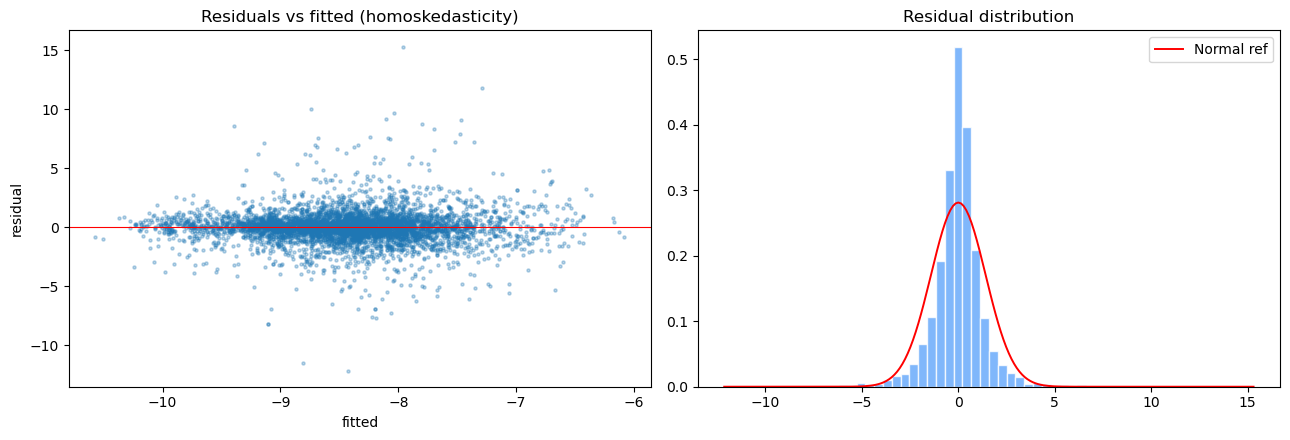

In [13]:
# ═════════════════════════════════════════════════════════════
# STEP 6 — Model evaluation & robustness
# ═════════════════════════════════════════════════════════════
Y_EVAL = "grdp_growth_pct"
sub = pdat[[Y_EVAL]+X].dropna()
fe = PanelOLS(sub[Y_EVAL], sub[X], entity_effects=True, time_effects=True,
              drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
resid = fe.resids.values.ravel(); fitted = fe.fitted_values.values.ravel()

# diagnostic statistics
jb_stat, jb_p = jarque_bera(resid)
from scipy import stats as _st
skew=_st.skew(resid); exkurt=_st.kurtosis(resid)
_ex = sub[X].loc[fe.resids.index]
bp_lm, bp_p, _, _ = het_breuschpagan(resid, np.column_stack([np.ones(len(_ex)), _ex.values]))
dw = durbin_watson(resid)
print("RESIDUAL DIAGNOSTICS")
print(f"  Jarque-Bera (normality)        stat={jb_stat:.1f}  p={jb_p:.4g}  -> {'non-normal' if jb_p<0.05 else 'normal'}")
print(f"  Breusch-Pagan (heterosked.)    LM={bp_lm:.1f}  p={bp_p:.4g}  -> {'heteroskedastic' if bp_p<0.05 else 'homoskedastic'}")
print(f"  Durbin-Watson (autocorr.)      {dw:.3f}  (2 = none)")
print(f"  Skewness={skew:.3f}  Excess kurtosis={exkurt:.3f}")
print("\n  -> heavy tails / heteroskedasticity expected in regency panels; handled by")
print("     robust SEs (clustered / Driscoll-Kraay) + large-n CLT, NOT by changing the model.")

fig, ax = plt.subplots(1, 2, figsize=(13,4.5))
ax[0].scatter(fitted, resid, s=5, alpha=0.3); ax[0].axhline(0, color="red", lw=.8)
ax[0].set_title("Residuals vs fitted (homoskedasticity)"); ax[0].set_xlabel("fitted"); ax[0].set_ylabel("residual")
ax[1].hist(resid, bins=60, density=True, color="#60a5fa", edgecolor="white", alpha=.8)
_xx=np.linspace(resid.min(),resid.max(),200); ax[1].plot(_xx,_st.norm.pdf(_xx,resid.mean(),resid.std()),"r-",lw=1.4,label="Normal ref")
ax[1].set_title("Residual distribution"); ax[1].legend(); plt.tight_layout(); plt.show()

In [14]:
# Coefficient stability across control ladder (key flood predictor)
KEY = FLOOD[-1] if "sector"=="growth" else FLOOD[-1]
KEY = "fasum_damaged_log" if "fasum_damaged_log" in FLOOD else FLOOD[-1]
Y_EVAL = "grdp_growth_pct"
ladder = [("flood only", FLOOD), ("+ log_population", FLOOD+["log_population"]),
          ("+ rls_years (FULL)", FLOOD+CONTROLS)]
print(f"Coefficient stability of {KEY} on {Y_EVAL} (Driscoll-Kraay):\n")
print(f"  specification               beta        p")
bs=[]
for nm,xv in ladder:
    sub=pdat[[Y_EVAL]+xv].dropna()
    r=PanelOLS(sub[Y_EVAL],sub[xv],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    bs.append(r.params[KEY]); print(f"  {nm:<22}{r.params[KEY]:>10.4f}{r.pvalues[KEY]:>9.4f}")
print(f"  range={max(bs)-min(bs):.4f} -> {'STABLE (control-insensitive)' if max(bs)-min(bs)<abs(np.mean(bs))*0.3 else 'sensitive'}")

# robustness to SE & sample
print(f"\nRobustness of {KEY} to SE & sample:")
print(f"  variant                         beta        p")
sub=pdat[[Y_EVAL]+X].dropna()
mm=PanelOLS(sub[Y_EVAL],sub[X],entity_effects=True,time_effects=True,drop_absorbed=True)
for lab,cov in [("clustered",dict(cov_type="clustered",cluster_entity=True)),("Driscoll-Kraay",dict(cov_type="kernel")),("robust",dict(cov_type="robust"))]:
    r=mm.fit(**cov); print(f"  {lab:<26}{r.params[KEY]:>10.4f}{r.pvalues[KEY]:>9.4f}")
for lo,hi in [(2016,2020),(2021,2025)]:
    s2=panel[(panel.year>=lo)&(panel.year<=hi)].set_index(["bps_kab_code","year"])
    s2=s2[[Y_EVAL]+X].dropna()
    r=PanelOLS(s2[Y_EVAL],s2[X],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    print(f"  {f'subsample {lo}-{hi}':<26}{r.params[KEY]:>10.4f}{r.pvalues[KEY]:>9.4f}")

Coefficient stability of fasum_damaged_log on grdp_growth_pct (Driscoll-Kraay):

  specification               beta        p
  flood only               -0.1170   0.0000
  + log_population         -0.1165   0.0000
  + rls_years (FULL)       -0.1156   0.0000
  range=0.0013 -> STABLE (control-insensitive)

Robustness of fasum_damaged_log to SE & sample:
  variant                         beta        p
  clustered                    -0.1156   0.0010
  Driscoll-Kraay               -0.1156   0.0000
  robust                       -0.1156   0.0000
  subsample 2016-2020          -0.1128   0.0000
  subsample 2021-2025          -0.1131   0.0000


## STEP 7 — Model fit summary (AIC / BIC / R² / F / RMSE)

Reference metrics for this specification. **Important:** AIC and BIC are *relative* measures — a single value is not interpretable on its own; it is only meaningful when **compared across files** on the same outcome (e.g. this file's AIC vs the 7-variable file's AIC for growth, or 3-dim vs 7-var for sectors). Record these values and compare them in `9b_model_comparison_3dim_vs_7comp.ipynb`.

- **within-R² / adj. within-R²** — variation explained within regencies (adjusted penalises extra parameters)
- **AIC / BIC** — fit penalised for complexity; lower = better; BIC penalises parameters more strongly
- **log-likelihood** — model fit (higher = better)
- **F-statistic** — joint significance of all regressors
- **RMSE** — residual standard deviation (typical prediction error)

In [16]:
# ═════════════════════════════════════════════════════════════
# STEP 7 — Model fit summary per sector
# ═════════════════════════════════════════════════════════════
def model_fit_summary(res, n_params):
    n = res.nobs
    return {
        "within_R2":     res.rsquared_within,
        "adj_within_R2": 1 - (1 - res.rsquared_within) * (n - 1) / (n - n_params - 1),
        "AIC":           2 * n_params - 2 * res.loglik,
        "BIC":           n_params * np.log(n) - 2 * res.loglik,
        "logLik":        res.loglik,
        "RMSE":          res.resids.std(),
        "n":             int(n),
    }

# per-sector fit metrics, then aggregate (17 sectors -> summary stats)
fit_rows = []
for s in SECTORS:
    sub = pdat[[f"{s}_growth"] + X].dropna()
    r = PanelOLS(sub[f"{s}_growth"], sub[X], entity_effects=True, time_effects=True,
                 drop_absorbed=True).fit(cov_type="kernel")
    m = model_fit_summary(r, len(X)); m["sector"] = s.replace("grdp_", "")
    fit_rows.append(m)
fitdf = pd.DataFrame(fit_rows).set_index("sector")

print(f"MODEL FIT PER SECTOR ({len(FLOOD)}-variable flood spec) — AIC/BIC/within-R2:\n")
print(fitdf[["within_R2", "adj_within_R2", "AIC", "BIC", "RMSE"]].round(3).to_string())
print(f"""
  AGGREGATE across 17 sectors:
    within-R2 : mean={fitdf['within_R2'].mean():.4f}  range=[{fitdf['within_R2'].min():.4f}, {fitdf['within_R2'].max():.4f}]
    AIC       : mean={fitdf['AIC'].mean():.0f}  range=[{fitdf['AIC'].min():.0f}, {fitdf['AIC'].max():.0f}]
    BIC       : mean={fitdf['BIC'].mean():.0f}  range=[{fitdf['BIC'].min():.0f}, {fitdf['BIC'].max():.0f}]

  To compare 3-dim vs 7-var at sector level: compare the SAME sector's AIC/BIC
  across the two files (lower = better). Aggregate mean AIC/BIC gives the overall
  picture; BIC is the parsimony-strict criterion. Single values are reference only.""")

MODEL FIT PER SECTOR (7-variable flood spec) — AIC/BIC/within-R2:

                 within_R2  adj_within_R2        AIC        BIC   RMSE
sector                                                                
A_agriculture       -0.002         -0.004  19503.587  19561.542  1.988
B_mining            -0.005         -0.007  26252.618  26310.114  4.783
C_manufacturing      0.003          0.001  24582.857  24640.804  3.451
D_electricity       -0.002         -0.004  25696.278  25754.125  4.015
E_water              0.007          0.005  22093.338  22151.029  2.825
F_construction       0.017          0.015  24291.979  24349.934  3.336
G_trade             -0.002         -0.004  20213.386  20271.341  2.147
H_transport         -0.003         -0.005  29254.966  29312.921  5.704
I_accommodation     -0.005         -0.007  25443.401  25501.356  3.778
J_infocomm           0.035          0.033  21473.431  21531.368  2.471
K_finance            0.002         -0.000  24346.511  24404.378  3.444
L_realesta

## STEP 8 — Save sector results → fit_9d.json + master table (mirror of 9b)

In [33]:
# ═════════════════════════════════════════════════════════════
# STEP 8 — Save per-sector results
# ═════════════════════════════════════════════════════════════
# ── SAVE sector results to fit_9d.json (mirror of 9b, 7-component spec) ──
import json
from statsmodels.stats.multitest import multipletests

# `res` (clustered + BH) and `se` (CD + pcl/pdk) exist above — same as 9b.
_se = se.copy()
for f in FLOOD:
    _se[f"pdkBH_{f}"] = multipletests(_se[f"pdk_{f}"].values, method="fdr_bh")[1]
    _se[f"pclBH_{f}"] = multipletests(_se[f"pcl_{f}"].values, method="fdr_bh")[1]

def _beta_lookup(sector, f):
    r = res[res["sector"] == sector]
    col = f"b_{f}" if f"b_{f}" in res.columns else None
    if col is not None and len(r):
        return float(r[col].iloc[0])
    return None

# 7-component dimension names (event + 6 components), derived from FLOOD
_dim_name = {FLOOD[0]: "event"}
for c in COMPONENTS:
    _dim_name[f"{c}_log"] = c          # deaths, missing, injured, house_flooded, ...

sectors_out = {}
for _, r in _se.iterrows():
    sec = r["sector"]
    dims = {}
    for f in FLOOD:
        pcl = float(r[f"pclBH_{f}"]); pdk = float(r[f"pdkBH_{f}"])
        sig_cl, sig_dk = pcl < 0.05, pdk < 0.05
        flag = ("**" if sig_cl and sig_dk else
                "~cl" if sig_cl else
                "~dk" if sig_dk else "")
        dims[_dim_name[f]] = {
            "beta": _beta_lookup(sec, f),
            "pBH_clustered": pcl, "pBH_DK": pdk, "flag": flag,
            "sig_any": bool(sig_cl or sig_dk),
        }
    sectors_out[sec] = {"CD": float(r["CD"]),
                        "overall_F_pval": float(r["overall_F_pval"]),
                        "flood_block_pval_cl": float(r["flood_block_pval_cl"]),
                        "flood_block_pval_dk": float(r["flood_block_pval_dk"]),
                        "model_significant": bool(r["model_significant"]),
                        "dims": dims}

payload = {
    "file": "9d", "spec": "7-component (disaggregated)", "outcome": "sector growth",
    "n_sectors": len(sectors_out),
    "flag_legend": {"**": "robust (sig both SE)", "~cl": "clustered-only",
                    "~dk": "DK-only", "": "n.s."},
    "model_note": "model_significant = flood block jointly significant via Wald test (all 7 flood coefs = 0, p<0.05); overall_F_pval (all predictors) reported for context only",
    "sectors": sectors_out,
}
with open("../data/processed/fit_9d.json", "w") as _f:
    json.dump(payload, _f, indent=2)

_robust = [(s, d) for s, v in sectors_out.items() for d, x in v["dims"].items() if x["flag"] == "**"]
_sugg   = [(s, d) for s, v in sectors_out.items() for d, x in v["dims"].items() if x["flag"].startswith("~")]
print(f"✓ saved fit_9d.json — {len(sectors_out)} sectors")
print(f"  ROBUST (**):     {len(_robust)} -> {_robust}")
print(f"  SUGGESTIVE (~):  {len(_sugg)}")
print(f"  (the rest are n.s.)")

✓ saved fit_9d.json — 17 sectors
  ROBUST (**):     3 -> [('G_trade', 'fasum_damaged'), ('I_accommodation', 'fasum_damaged'), ('RSTU_other', 'fasum_damaged')]
  SUGGESTIVE (~):  11
  (the rest are n.s.)


## STEP 9 — Master sector table & grouped summary (for the thesis write-up)

In [20]:
# ═════════════════════════════════════════════════════════════
# STEP 9 — Master sector table & grouped summary
# ═════════════════════════════════════════════════════════════
# ── Master sector table + grouped summary (printed for the thesis) ──
# Uses `sectors_out` built in the save cell above. 7 components per sector.
_DIMS = list(next(iter(sectors_out.values()))["dims"].keys())  # event + 6 components
print("MASTER SECTOR TABLE (7-component) — beta | pBH(clustered) | pBH(DK) | flag")
print("  flags: ** = sig BOTH SEs (robust)   ~cl = clustered only   ~dk = DK only\n")
for sec, v in sectors_out.items():
    print(f"{sec}")
    for dim in _DIMS:
        d = v["dims"][dim]
        b = d["beta"]; pcl = d["pBH_clustered"]; pdk = d["pBH_DK"]; fl = d["flag"]
        bstr = f"{b:+.3f}" if b is not None else "  n/a "
        print(f"   {dim:<16} {bstr}  pCL={pcl:.3f}  pDK={pdk:.3f}  {fl}")
    print()

# grouped summary by SE agreement
print("=" * 74)
print("SUMMARY — significant sector x component effects, grouped by SE agreement")
print("(BH-FDR corrected; model_significant = flood block jointly sig via Wald)\n")

def _collect(flag_test):
    out = []
    for sec, v in sectors_out.items():
        for dim, d in v["dims"].items():
            if flag_test(d["flag"]):
                out.append((sec, dim, d["beta"], d["pBH_clustered"], d["pBH_DK"],
                            v.get("model_significant", True)))
    return out

_groups = [
    ("1. ROBUST — significant under BOTH clustered AND Driscoll-Kraay:",
     lambda f: f == "**"),
    ("2. CLUSTERED SE ONLY — significant under clustered, NOT DK:",
     lambda f: f == "~cl"),
    ("3. DRISCOLL-KRAAY SE ONLY — significant under DK, NOT clustered:",
     lambda f: f == "~dk"),
]
for _title, _test in _groups:
    _items = _collect(_test)
    print(_title)
    if not _items:
        print("   (none)")
    for sec, dim, b, pcl, pdk, msig in _items:
        bstr = f"{b:+.3f}" if b is not None else "n/a"
        print(f"   {sec:<14} {dim:<16} beta={bstr}  pCL={pcl:.3f}  pDK={pdk:.3f}")
    print()

MASTER SECTOR TABLE (7-component) — beta | pBH(clustered) | pBH(DK) | flag
  flags: ** = sig BOTH SEs (robust)   ~cl = clustered only   ~dk = DK only

A_agriculture
   event            +0.086  pCL=0.564  pDK=0.631  
   deaths           -0.060  pCL=0.794  pDK=0.657  
   missing          -0.141  pCL=0.936  pDK=0.680  
   injured          -0.026  pCL=0.925  pDK=0.669  
   house_flooded    -0.017  pCL=0.777  pDK=0.642  
   house_damaged    +0.030  pCL=0.678  pDK=0.381  
   fasum_damaged    -0.079  pCL=0.257  pDK=0.139  

B_mining
   event            +0.189  pCL=0.564  pDK=0.562  
   deaths           -0.118  pCL=0.794  pDK=0.657  
   missing          +0.249  pCL=0.936  pDK=0.641  
   injured          +0.047  pCL=0.925  pDK=0.830  
   house_flooded    -0.028  pCL=0.830  pDK=0.642  
   house_damaged    -0.033  pCL=0.800  pDK=0.773  
   fasum_damaged    -0.091  pCL=0.485  pDK=0.488  

C_manufacturing
   event            +0.094  pCL=0.632  pDK=0.594  
   deaths           +0.229  pCL=0.794  pDK=